# CSE 4095 — Class 5 v3
## Feature Engineering → Importance → Selection → Randomized Search
Protect the final test set throughout model development.

## 1. Load and inspect Auto MPG

**Goal:** understand the data before building a model.

One row describes a vehicle. The **target** is `mpg` (miles per gallon). A **feature** is an input we might use to predict that target. This is a regression task because the prediction is a numerical value.

We will load the data, inspect its structure, check missing values, and visualize MPG. We are not choosing engineered features or fitting a model yet.

The first code cell records Python and library versions. Numerical summaries are generated from each run's results, because small implementation differences between environments can affect forest scores and close rankings. The recorded versions describe the environment; they do not install or pin it.

In [1]:
import platform
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Record the environment for this execution; a seed alone does not pin versions.
library_versions = {
    "Python": platform.python_version(),
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
}
print("Execution environment")
for library, version in library_versions.items():
    print(f"{library}: {version}")

DATA_URL = "https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv"

# Pandas recognizes blank fields as missing. Also recognize "?" if present.
df = pd.read_csv(DATA_URL, na_values=["?"])

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")
print("Column names:", df.columns.tolist())
display(df.head())

Execution environment
Python: 3.12.14
NumPy: 2.5.4
pandas: 3.0.1
SciPy: 1.18.1
scikit-learn: 1.9.1
Matplotlib: 3.11.2


Rows: 398 | Columns: 7
Column names: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


### Read the structure

`df` is our DataFrame: a table with named columns.

- `shape` gives (number of rows, number of columns).
- `head()` shows the first five rows; it does not summarize the whole dataset.
- `info()` reports column types and counts of nonmissing values. `int64` and `float64` are numerical types; a float can also represent missing values as `NaN`.

Read the first displayed row as a vehicle description, rather than as a list of unrelated numbers.

In [2]:
df.info()

print("\nMissing values per column:")
display(df.isna().sum().rename("missing_count").to_frame())

print("Rows with at least one missing value:")
display(df.loc[df.isna().any(axis=1)])

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    396 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model-year    398 non-null    int64  
dtypes: float64(4), int64(3)
memory usage: 21.9 KB

Missing values per column:


,missing_count
mpg,0
cylinders,0
displacement,0
horsepower,2
weight,0
acceleration,0
model-year,0


Rows with at least one missing value:


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
32,25.0,4,98.0,NaN,2046,19.0,71
126,21.0,6,200.0,NaN,2875,17.0,74


### Summarize the values

`describe()` reports the number of known values, mean, standard deviation, minimum, quartiles, and maximum for each numerical column. The 50% row is the median. Compare the `count` row across columns to confirm which column has fewer known values.

We will leave missing values in place during this inspection. Any filling strategy used for modeling will learn its replacement values from training data only, and within each cross-validation training fold.

In [3]:
display(df.describe().round(2))

,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
count,398.00,398.00,398.00,396.00,398.00,398.00,398.00
mean,23.51,5.45,193.43,104.19,2970.42,15.57,76.01
std,7.82,1.70,104.27,38.40,846.84,2.76,3.70
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.50,4.00,104.25,75.00,2223.75,13.82,73.00
50%,23.00,4.00,148.50,92.00,2803.50,15.50,76.00
75%,29.00,8.00,262.00,125.00,3608.00,17.18,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


### Visualize the prediction target

A histogram groups MPG values into ranges. The horizontal axis is fuel economy; the vertical axis counts vehicles in each range. Use it to describe where the observations are concentrated and whether the distribution has a long tail.

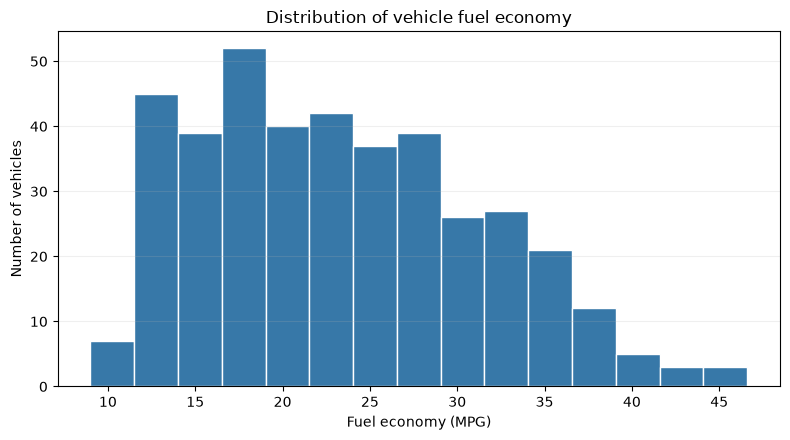

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["mpg"], bins=15, color="#3778A8", edgecolor="white")
ax.set_title("Distribution of vehicle fuel economy")
ax.set_xlabel("Fuel economy (MPG)")
ax.set_ylabel("Number of vehicles")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

### Data interpretation

Each row represents a vehicle, with MPG as a continuous numerical target and six potential numerical predictors. The inspection outputs above report the row count, missing values, descriptive statistics, and MPG distribution.

**Student explanation of missing horsepower:**

> because it would make it so it looks like they have 0 horse power which has a meaning

**AI feedback:** Missing horsepower is unknown, whereas zero horsepower would be a numerical measurement with a different meaning. Median imputation is fitted within each training fold later in the workflow.

## 2. Define X/y and create one train/test split

**Goal:** reserve a final check before we start making modeling choices.

- `X` contains the six potential input features. `drop(columns="mpg")` makes a table without the target column; it does not change `df`.
- `y` contains the MPG values we want to predict.
- The training set is used for development, including cross-validation.
- The test set stays set aside until the final evaluation. We will not use it to choose engineered features, feature subsets, or hyperparameters.

`test_size=0.20` reserves about 20% of rows. `random_state=42` makes the random split reproducible when we rerun the same code on the same data; 42 is an arbitrary seed, not a setting chosen to improve the score.

We split before filling missing values. Later, any replacement values will be learned using only the training portion of each cross-validation fold.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="mpg")
y = df["mpg"]

# Split inputs and targets together so each vehicle keeps its correct MPG.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
)

print(f"Training set: {len(X_train)} vehicles, {X_train.shape[1]} features")
print(f"Test set reserved: {len(X_test)} vehicles")
print("Target:", y.name)
print("Input features:", X.columns.tolist())
print("Keep this split fixed throughout the assignment.")

Training set: 318 vehicles, 6 features
Test set reserved: 80 vehicles
Target: mpg
Input features: ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']
Keep this split fixed throughout the assignment.


### Why protect the test set?

**Student explanation:**

> Because the test set stops being a held-out test set once you use it to make decisions. Every time you check the test score and then change features, information from the test set leaks into your model-building process. You are effectively selecting the feature set that happens to do well on that particular test sample—including its noise and quirks.

Training-data cross-validation supplies the development comparisons. The reserved test set assesses choices fixed before final evaluation. The assignment-required initial inspection used all rows before splitting; no modeling decision used the test rows.

## 3. Mean baseline + untuned Random Forest baseline

**Goal:** establish reference results before engineering features or tuning a model.

The **mean predictor** ignores vehicle features and predicts the average MPG learned from its training data for every vehicle. This asks: how well can we do without using the inputs at all?

An **untuned Random Forest** combines predictions from many decision trees. Each tree learns rules using vehicle features, and the forest averages their predictions. We will use the original six inputs, default forest settings, and `random_state=42`.

### How we measure errors

- **MAE:** average absolute difference between actual and predicted MPG. An MAE of 3 means errors average 3 MPG in magnitude, not that every prediction misses by 3. Lower is better. This is our primary comparison metric.
- **RMSE:** square the errors, average them, then take the square root. It is also in MPG units, but large errors have more influence. Lower is better.
- **R²:** compares squared errors with a constant prediction equal to the evaluation set's mean. A perfect result is 1; 0 matches that reference; negative values are possible. Higher is better. A mean predictor trained on different rows can have a negative validation R².

For example, actual MPG `[20, 30]` and predictions `[23, 25]` give absolute errors `[3, 5]`, so MAE is `(3 + 5) / 2 = 4` MPG. RMSE is `sqrt((9 + 25) / 2)`, about 4.12 MPG.

### Five-fold cross-validation uses only our 318 training vehicles

1. Shuffle the training rows reproducibly and divide them into five groups, called folds.
2. Fit a fresh model on four folds and evaluate predictions on the remaining fold.
3. Repeat until each fold has served as validation once.
4. Report the average errors and how much MAE varies across the five folds.

Both baselines use the same folds. In each fold, the mean predictor learns its average from that fold's training rows only.

For the forest, a **pipeline** first fills missing numerical values with column medians and then fits the model. Cross-validation fits this entire pipeline separately for each fold, so the median also comes only from that fold's training rows. We choose median filling as a simple baseline strategy, not as a claim that the missing horsepower is truly the median.

We will reuse this fixed CV procedure for later comparisons. The final 80 test vehicles are not involved.

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

cv = KFold(n_splits=5, shuffle=True, random_state=42)

mean_baseline = DummyRegressor(strategy="mean")
mean_baseline.fit(X_train, y_train)
print(f"Mean predictor fitted on all training rows: {mean_baseline.constant_[0, 0]:.2f} MPG")
print("This fitted predictor gives the same MPG prediction for every vehicle.")

rf_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestRegressor(random_state=42)),
])

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

baseline_models = {
    "Mean predictor": mean_baseline,
    "Untuned Random Forest": rf_baseline,
}

Mean predictor fitted on all training rows: 23.61 MPG
This fitted predictor gives the same MPG prediction for every vehicle.


### Run the comparison

`cross_validate()` creates fresh fitted copies for the folds, even though we fitted the mean predictor above to display the overall training mean.

Scikit-learn uses negative error scores so that a larger score always means better performance. We multiply MAE and RMSE scores by −1 to report ordinary positive errors. R² keeps its original sign.

The returned keys `test_mae`, `test_rmse`, and `test_r2` refer to each CV validation fold. The word `test` in these library keys does **not** refer to our reserved `X_test` or `y_test`.

The summary reports averages of the five fold metrics; its standard deviation describes the spread of the five MAEs. It is not a confidence interval.

In [7]:
baseline_cv_results = {}
summary_rows = []
fold_mae = {}

for name, model in baseline_models.items():
    results = cross_validate(
        model, X_train, y_train,
        cv=cv, scoring=scoring, error_score="raise",
    )
    baseline_cv_results[name] = results
    mae = -results["test_mae"]
    rmse = -results["test_rmse"]
    fold_mae[name] = mae
    summary_rows.append({
        "Model": name,
        "Mean CV MAE (MPG)": mae.mean(),
        "CV MAE Std (MPG)": mae.std(),
        "Mean CV RMSE (MPG)": rmse.mean(),
        "Mean CV R2": results["test_r2"].mean(),
    })

baseline_summary = pd.DataFrame(summary_rows).set_index("Model")
fold_mae_table = pd.DataFrame(fold_mae, index=range(1, 6))
fold_mae_table.index.name = "Validation fold"

print("Baseline comparison: averages across five validation folds")
display(baseline_summary.round(3))
print("MAE for each fold (MPG)")
display(fold_mae_table.round(3))

display(Markdown(
    f"**Computed baseline summary:** The untuned forest has mean CV MAE "
    f"**{fold_mae['Untuned Random Forest'].mean():.2f} MPG**, compared with "
    f"**{fold_mae['Mean predictor'].mean():.2f} MPG** for the fold-trained mean predictor. "
    f"The forest's MAE is lower in "
    f"**{int((fold_mae['Untuned Random Forest'] < fold_mae['Mean predictor']).sum())} "
    f"of {cv.get_n_splits()} folds**. MAE measures average absolute error, not the error of every vehicle."
))

Baseline comparison: averages across five validation folds


,Mean CV MAE (MPG),CV MAE Std (MPG),Mean CV RMSE (MPG),Mean CV R2
Model,,,,
Mean predictor,6.702,0.452,7.923,-0.017
Untuned Random Forest,2.002,0.129,2.921,0.859


MAE for each fold (MPG)


,Mean predictor,Untuned Random Forest
Validation fold,,
1,7.025,2.126
2,6.747,2.023
3,6.359,1.777
4,6.059,2.123
5,7.321,1.962


**Computed baseline summary:** The untuned forest has mean CV MAE **2.00 MPG**, compared with **6.70 MPG** for the fold-trained mean predictor. The forest's MAE is lower in **5 of 5 folds**. MAE measures average absolute error, not the error of every vehicle.

### Baseline interpretation

**Student interpretation:** The untuned Random Forest is a control for the later feature experiments. Keeping the same model settings, data split, and metric makes the comparison fairer: any score change can then be examined as a consequence of changing the representation, rather than simultaneously switching models or tuning settings. Random Forests can already capture some nonlinear relationships and interactions, so engineered ratios may add little predictive benefit.

**AI feedback:** A decrease in mean CV MAE is an observed improvement on these folds, not proof that it will persist on new data. Paired fold differences are more useful for comparing representations than the standard deviation of each model's MAE alone. Neither that spread nor a baseline comparison establishes statistical significance or rules out leakage.

## 4. Initial feature engineering

**Goal:** propose meaningful representations, choose them with a rationale, then evaluate them fairly.

A forest can learn relationships between inputs, but a ratio may express a useful relationship more directly. Engineered features do not add new measurements; they reorganize information we already have. Improvement is a hypothesis to test, not a guarantee.

### Selected features — all four candidates

| Candidate | Formula | Interpretation and hypothesis |
|---|---|---|
| `power_to_weight` | `horsepower / weight` | Power relative to vehicle weight. Similar horsepower can represent different power relative to the load being moved. This balance might help distinguish MPG behavior. |
| `displacement_per_cylinder` | `displacement / cylinders` | Average engine displacement per cylinder. It expresses engine size relative to cylinder count, which might distinguish engine configurations with different MPG behavior. |
| `power_per_displacement` | `horsepower / displacement` | Power relative to engine displacement. Vehicles with similar engine size can produce different power; this relationship might be relevant to MPG. It is not a direct measurement of fuel efficiency. |
| `weight_per_cylinder` | `weight / cylinders` | Vehicle weight relative to cylinder count. It is a rough measure of vehicle load relative to this aspect of engine configuration and might help predict MPG. It does not imply that each cylinder carries an equal share of the weight. |

These are candidate associations, not causal claims. They share raw inputs and may be correlated or redundant. Cross-validation will decide whether adding the chosen features helps this model.

**Simple example:** Two vehicles both have 100 horsepower, but one weighs 2,000 and the other 4,000 in the dataset's weight units. Their power-to-weight ratios are 0.05 and 0.025: the first has twice the power per unit of weight. This does not by itself tell us which one has higher MPG.

### Choice and predictions recorded before evaluation

**Student choice:** Test all four candidate features, exceeding the assignment minimum of three. The table records each formula and rationale.

**Student predictions:**

- Power-to-weight: I expect higher values to be associated with lower MPG, with the strongest negative relationship of the four.
- Displacement per cylinder: I expect a negative relationship with MPG. The displacement prediction refers here to the engineered ratio listed above.
- Power per displacement: I expect a weaker negative relationship.
- Weight per cylinder: I expect the weakest negative relationship.

These are hypotheses, not findings. "Negative" describes an expected association, not proof that changing a feature causes MPG to change. The ratios use different scales, so comparing raw slope magnitudes would not fairly rank them. Predictive usefulness and the direction of an association are different questions. This first CV experiment tests all four features as a group, not these individual directional predictions.

The implementation uses training data, checks denominator validity, and preserves missing values for fold-specific imputation. We will compare original inputs with original plus engineered inputs using the same untuned forest and CV folds. The final test set stays reserved.


In [8]:
def engineer_features(data):
    """Add the four chosen ratios without learning values from other rows."""
    result = data.copy()

    # Nonpositive denominators are invalid for these ratios; leave them missing.
    safe_weight = result["weight"].where(result["weight"] > 0)
    safe_cylinders = result["cylinders"].where(result["cylinders"] > 0)
    safe_displacement = result["displacement"].where(result["displacement"] > 0)

    result["power_to_weight"] = result["horsepower"] / safe_weight
    result["displacement_per_cylinder"] = result["displacement"] / safe_cylinders
    result["power_per_displacement"] = result["horsepower"] / safe_displacement
    result["weight_per_cylinder"] = result["weight"] / safe_cylinders
    return result


# Develop features on training data only. Keep the final test set reserved.
X_train_engineered = engineer_features(X_train)
engineered_columns = [
    "power_to_weight", "displacement_per_cylinder",
    "power_per_displacement", "weight_per_cylinder",
]

print(f"Original inputs: {X_train.shape[1]} | Original + engineered: {X_train_engineered.shape[1]}")
print("Nonpositive denominator counts in training data:")
display(X_train[["weight", "cylinders", "displacement"]].le(0).sum().to_frame("count"))
print("Examples of the four new features:")
display(X_train_engineered[engineered_columns].head().round(4))
print("Missing values in the new features:")
display(X_train_engineered[engineered_columns].isna().sum().to_frame("missing_count"))

Original inputs: 6 | Original + engineered: 10
Nonpositive denominator counts in training data:


,count
weight,0
cylinders,0
displacement,0


Examples of the four new features:


,power_to_weight,displacement_per_cylinder,power_per_displacement,weight_per_cylinder
3,0.0437,38.00,0.4934,429.125
18,0.0413,24.25,0.9072,532.500
376,0.0336,22.75,0.7473,506.250
248,0.0333,22.75,0.6593,450.000
177,0.0353,28.75,0.8261,673.500


Missing values in the new features:


,missing_count
power_to_weight,1
displacement_per_cylinder,0
power_per_displacement,1
weight_per_cylinder,0


### Why these calculations can happen before CV

Each formula uses only values from the same vehicle. It does not learn a mean, median, threshold, or coefficient from other rows. We can therefore compute these fixed ratios before cross-validation without sharing learned information between folds.

Missing horsepower remains missing in horsepower-based ratios. We do not replace it with zero. During CV, the pipeline's imputer will learn a separate median for each raw or engineered column from that fold's training portion.

The function retains all original inputs and adds four columns, giving ten inputs in total. It makes a copy so the original six-feature representation remains available for comparison.

## 5. Original vs. engineered representation

**Question:** Does adding the four selected ratios improve the untuned forest's predictions?

- **Model A:** the original six inputs.
- **Model B:** the original six inputs plus our four ratios.
- **Fixed controls:** the same Random Forest defaults, forest seed, median-imputation strategy, 318 training vehicles, five CV folds, and MAE scoring.

We reuse Model A's saved fold errors from Section 3. `cross_val_score` will fit fresh copies of the same pipeline for Model B. Adding columns also changes the model's available splitting choices; that is part of the representation experiment.

Both models evaluate the same vehicles within each validation fold. The per-fold difference is **engineered MAE minus original MAE**: a negative difference favors the engineered representation. The fold standard deviation describes variability, not a significance test.

**Interpretation convention adopted during this review:** An absolute mean MAE difference below about **0.05 MPG**—roughly 2.5% of an MAE near 2 MPG—is treated as practically negligible for this project. This is a retrospective reporting yardstick, not a threshold specified before the experiments or a statistical significance rule. Paired fold differences provide context for the comparison; their descriptive spread is not a confidence interval.

In [9]:
from sklearn.model_selection import cross_val_score

original_mae = -baseline_cv_results["Untuned Random Forest"]["test_mae"]
engineered_mae = -cross_val_score(
    rf_baseline, X_train_engineered, y_train,
    cv=cv, scoring="neg_mean_absolute_error", error_score="raise",
)

engineering_comparison = pd.DataFrame([
    {
        "Feature set": "Original",
        "Number of features": X_train.shape[1],
        "Mean CV MAE (MPG)": original_mae.mean(),
        "CV MAE Std (MPG)": original_mae.std(),
    },
    {
        "Feature set": "Original + engineered",
        "Number of features": X_train_engineered.shape[1],
        "Mean CV MAE (MPG)": engineered_mae.mean(),
        "CV MAE Std (MPG)": engineered_mae.std(),
    },
]).set_index("Feature set")

engineering_fold_comparison = pd.DataFrame({
    "Original MAE": original_mae,
    "Engineered MAE": engineered_mae,
    "Engineered minus original": engineered_mae - original_mae,
}, index=range(1, 6))
engineering_fold_comparison.index.name = "Validation fold"

display(engineering_comparison.round(3))
display(engineering_fold_comparison.round(3))
print(f"Mean MAE reduction: {original_mae.mean() - engineered_mae.mean():.4f} MPG")
print("Positive reduction favors engineered features; negative reduction favors original features.")

practical_mae_difference = 0.05
engineering_differences = engineered_mae - original_mae
display(Markdown(
    f"**Computed engineering summary:** Original inputs: **{original_mae.mean():.2f} MPG**; "
    f"original plus ratios: **{engineered_mae.mean():.2f} MPG**. "
    f"The mean paired difference (engineered minus original) is "
    f"**{engineering_differences.mean():+.4f} MPG**, with paired SD "
    f"**{engineering_differences.std(ddof=0):.4f} MPG**. "
    f"The engineered set improves **{int((engineering_differences < 0).sum())} "
    f"of {len(engineering_differences)} folds**. "
    f"The absolute mean difference is "
    f"{'below' if abs(engineering_differences.mean()) < practical_mae_difference else 'at or above'} "
    f"the practical reporting yardstick."
))

,Number of features,Mean CV MAE (MPG),CV MAE Std (MPG)
Feature set,,,
Original,6,2.002,0.129
Original + engineered,10,2.002,0.091


,Original MAE,Engineered MAE,Engineered minus original
Validation fold,,,
1,2.126,2.057,-0.069
2,2.023,2.094,0.071
3,1.777,1.831,0.054
4,2.123,2.021,-0.102
5,1.962,2.006,0.044


Mean MAE reduction: 0.0003 MPG
Positive reduction favors engineered features; negative reduction favors original features.


**Computed engineering summary:** Original inputs: **2.00 MPG**; original plus ratios: **2.00 MPG**. The mean paired difference (engineered minus original) is **-0.0003 MPG**, with paired SD **0.0708 MPG**. The engineered set improves **2 of 5 folds**. The absolute mean difference is below the practical reporting yardstick.

### Interpretation of the engineered representation

**Student interpretation:** As a group, the four engineered features did not provide a meaningful improvement. I would not add them just for prediction accuracy, because the observed change does not justify the additional complexity. A smaller standard deviation for one model does not establish that its average error is reliably better.

The group comparison cannot establish whether each individual feature is useful. Features could help, hurt, or overlap in ways that offset one another. Individual addition tests or feature ablations under controlled CV would address their incremental value. Comparing MAE does not establish the sign of a feature's relationship with MPG, and an experiment showing little benefit is still informative.

**AI feedback:** The original inputs already capturing similar relationships is a plausible explanation, not something this experiment proves. A leave-one-feature-out comparison means removing one feature at a time, rather than LeaveOneOut CV over vehicles. Importance can suggest those experiments; retraining and CV test their predictive consequences.

## 6. Built-in Random Forest feature importance

**Question:** Which inputs does the forest use to reduce training prediction error?

A regression tree repeatedly splits vehicles into groups. With the default squared-error criterion, built-in importance credits a feature for the weighted reductions in squared-error impurity achieved by its splits, averaged over the forest and normalized. The importances sum to 1.

An importance of 0.30 means about 30% of this normalized training splitting credit. It does not mean that the feature explains 30% of MPG or causes a 30% change in MPG.

We fit a fresh copy of the engineered pipeline on all training rows. We retain the ten-feature candidate representation for this diagnostic analysis; this does not override our conclusion that adding all four ratios did not improve mean CV MAE.

Built-in importance can favor features with many possible split values. Correlated features can share credit. It describes this fitted model, not a feature's universal value.

,Built-in importance (all training rows)
displacement,0.4129
horsepower,0.1653
cylinders,0.1162
weight,0.1053
model-year,0.0999
weight_per_cylinder,0.0299
displacement_per_cylinder,0.0242
acceleration,0.0190
power_to_weight,0.0137
power_per_displacement,0.0137


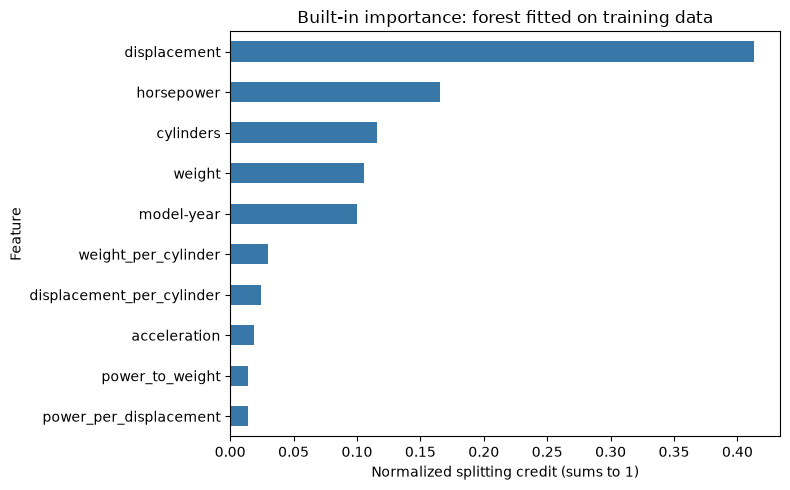

In [10]:
from sklearn.base import clone

engineered_model = clone(rf_baseline).fit(X_train_engineered, y_train)
feature_names = engineered_model.named_steps["imputer"].get_feature_names_out()
builtin_importance = pd.Series(
    engineered_model.named_steps["rf"].feature_importances_,
    index=feature_names,
    name="Built-in importance (all training rows)",
).sort_values(ascending=False)

display(builtin_importance.to_frame().round(4))

fig, ax = plt.subplots(figsize=(8, 5))
builtin_importance.sort_values().plot.barh(ax=ax, color="#3778A8")
ax.set_title("Built-in importance: forest fitted on training data")
ax.set_xlabel("Normalized splitting credit (sums to 1)")
ax.set_ylabel("Feature")
fig.tight_layout()
plt.show()

## 7. Permutation importance on CV validation folds

**Question:** How much worse does a fitted model predict when one feature's values are shuffled?

For each of our same five training-data CV folds:

1. Fit a fresh pipeline on four folds, including learning imputation medians there.
2. Measure predictions on the remaining validation fold.
3. Shuffle one validation feature at a time and measure the change in MAE, without retraining the model.
4. Repeat each shuffle ten times, then average its MAE increases.

We average the five fold means. With `scoring="neg_mean_absolute_error"`, the returned importance is shuffled MAE minus original MAE, so positive values mean worse errors after shuffling. **Do not negate these returned importances.**

For example, an importance of +0.5 MPG means shuffling that column increased MAE by 0.5 MPG on average. A value close to zero means little measured change for these models. A negative value means shuffling slightly improved error; it does not automatically prove that dropping and retraining without the feature would help.

We also collect built-in importances from these five fitted forests so we can compare rankings from the same model fits. The final 80-vehicle test set remains reserved.

Completed importance analysis for validation fold 1/5


Completed importance analysis for validation fold 2/5


Completed importance analysis for validation fold 3/5


Completed importance analysis for validation fold 4/5


Completed importance analysis for validation fold 5/5


,Mean MAE increase (MPG),Std across fold means (MPG)
model-year,1.5508,0.1721
displacement,1.1750,0.2842
horsepower,0.9394,0.2738
weight,0.7976,0.1172
cylinders,0.3760,0.2822
displacement_per_cylinder,0.0899,0.0370
weight_per_cylinder,0.0770,0.0977
power_per_displacement,0.0594,0.0251
acceleration,0.0523,0.0285
power_to_weight,0.0213,0.0203


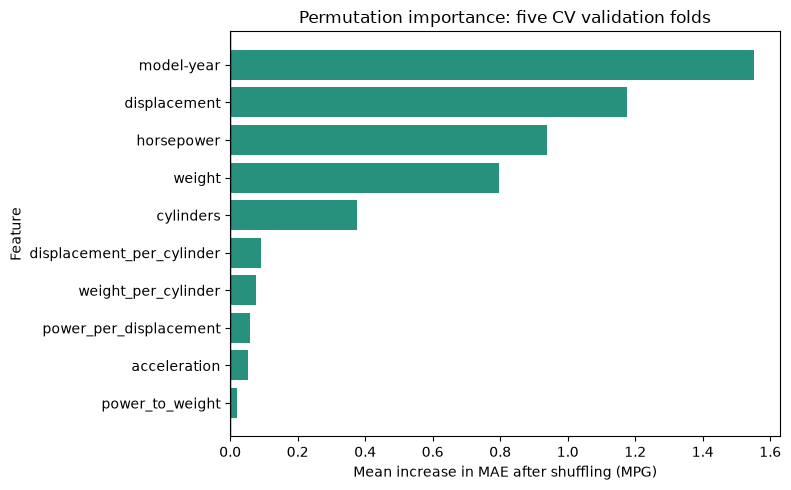

In [11]:
import numpy as np
from sklearn.inspection import permutation_importance

permutation_fold_rows = []
builtin_fold_rows = []

for fold, (fit_indices, val_indices) in enumerate(cv.split(X_train_engineered), start=1):
    X_fit = X_train_engineered.iloc[fit_indices]
    y_fit = y_train.iloc[fit_indices]
    X_val = X_train_engineered.iloc[val_indices]
    y_val = y_train.iloc[val_indices]

    fold_model = clone(rf_baseline).fit(X_fit, y_fit)
    result = permutation_importance(
        fold_model, X_val, y_val,
        scoring="neg_mean_absolute_error",
        n_repeats=10, random_state=42 + fold, n_jobs=1,
    )
    permutation_fold_rows.append(result.importances_mean)
    builtin_fold_rows.append(fold_model.named_steps["rf"].feature_importances_)
    print(f"Completed importance analysis for validation fold {fold}/5")

permutation_by_fold = pd.DataFrame(
    permutation_fold_rows, columns=X_train_engineered.columns, index=range(1, 6),
)
builtin_by_fold = pd.DataFrame(
    builtin_fold_rows, columns=X_train_engineered.columns, index=range(1, 6),
)
permutation_table = pd.DataFrame({
    "Mean MAE increase (MPG)": permutation_by_fold.mean(),
    "Std across fold means (MPG)": permutation_by_fold.std(ddof=0),
}).sort_values("Mean MAE increase (MPG)", ascending=False)

display(permutation_table.round(4))

plot_data = permutation_table.sort_values("Mean MAE increase (MPG)")
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(plot_data.index, plot_data["Mean MAE increase (MPG)"], color="#27917D")
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Permutation importance: five CV validation folds")
ax.set_xlabel("Mean increase in MAE after shuffling (MPG)")
ax.set_ylabel("Feature")
fig.tight_layout()
plt.show()

## 8. Compare importance rankings

Built-in importance asks about training split credit. Permutation importance asks about validation prediction error after disrupting a column. They use different units, so compare their rankings rather than their numerical magnitudes.

For a comparison using the same five forest fits, the table below averages built-in importances from those CV forests alongside their validation permutation importances. The full-training forest's built-in chart above is another view and may rank features slightly differently.

Correlated inputs can substitute for one another, so a feature can receive low importance even when it contains useful information. Shuffling a raw or engineered feature separately also breaks its relationships with other columns, including the formula linking a ratio to its raw inputs. Interpret these as model diagnostics, not as realistic interventions on a vehicle.

The reported permutation standard deviation is the spread of five fold means, each based on ten shuffles. It is descriptive, not a confidence interval or significance test. Neither importance method establishes the sign of a relationship, causation, or the effect of removing and retraining without a feature.

In [12]:
importance_comparison = pd.DataFrame({
    "Mean CV built-in importance": builtin_by_fold.mean(),
    "Mean validation MAE increase (MPG)": permutation_by_fold.mean(),
})
importance_comparison["Built-in rank"] = importance_comparison[
    "Mean CV built-in importance"
].rank(ascending=False, method="min").astype(int)
importance_comparison["Permutation rank"] = importance_comparison[
    "Mean validation MAE increase (MPG)"
].rank(ascending=False, method="min").astype(int)
importance_comparison["Engineered feature"] = importance_comparison.index.isin(engineered_columns)
importance_comparison = importance_comparison.sort_values("Permutation rank")
display(importance_comparison.round(4))

year_importance = importance_comparison.loc["model-year"]
display(Markdown(
    f"**Computed importance comparison:** Model year has built-in rank "
    f"**{int(year_importance['Built-in rank'])}** and permutation rank "
    f"**{int(year_importance['Permutation rank'])}**. "
    f"Shuffling it raises validation MAE by "
    f"**{year_importance['Mean validation MAE increase (MPG)']:.2f} MPG** on average."
))

,Mean CV built-in importance,Mean validation MAE increase (MPG),Built-in rank,Permutation rank,Engineered feature
model-year,0.1060,1.5508,5,1,False
displacement,0.3286,1.1750,1,2,False
horsepower,0.1666,0.9394,3,3,False
weight,0.1696,0.7976,2,4,False
cylinders,0.1352,0.3760,4,5,False
displacement_per_cylinder,0.0159,0.0899,8,6,True
weight_per_cylinder,0.0299,0.0770,6,7,True
power_per_displacement,0.0146,0.0594,10,8,True
acceleration,0.0184,0.0523,7,9,False
power_to_weight,0.0154,0.0213,9,10,True


**Computed importance comparison:** Model year has built-in rank **5** and permutation rank **1**. Shuffling it raises validation MAE by **1.55 MPG** on average.

### Interpretation and proposed ablation

**Student interpretation:** The difference between model year's built-in and permutation ranks surprises me. Built-in importance credits training splits, while validation permutation importance measures how much the fitted models rely on a column for prediction. Model year's usefulness may involve interactions or shared information, but the ranking difference alone does not reveal the mechanism.

Before removing power-to-weight, I proposed a controlled ablation using the same CV folds and forest settings: compare all ten inputs against the nine without that ratio, and compare the original six against those six plus the ratio. Repeated CV can then examine sensitivity to the partitions. Paired differences matter because the effect could be small.

**AI feedback:** These comparisons can support omitting the ratio for this workflow; they cannot establish that it is universally useless. Adding it to six inputs and removing it from ten are different conditional questions. Grouped or conditional permutation importance and removing other inputs remain possible future analyses, not experiments already performed.

### Training-only correlations and overlapping information

Spearman correlation describes pairwise monotonic association. The table uses the observed training values; missing pairs are omitted by pandas. It does not use the target or final test rows.

**AI feedback:** Strong relationships between some ratios and raw inputs support overlapping-information hypotheses. Weak pairwise correlations for power-to-weight do not demonstrate redundancy, and do not rule out nonlinear or multivariable overlap. The ablation's predictive outcome stands independently of an unproven mechanism. Correlation and model importance do not establish causation.

In [13]:
training_spearman = X_train_engineered.corr(method="spearman")
display(training_spearman.round(2))

correlation_pairs = [
    ("displacement_per_cylinder", "displacement"),
    ("power_per_displacement", "displacement"),
    ("power_to_weight", "horsepower"),
    ("power_to_weight", "weight"),
]
for first, second in correlation_pairs:
    print(f"Spearman({first}, {second}) = {training_spearman.loc[first, second]:+.3f}")

cylinder_rank = int(importance_comparison.loc["cylinders", "Permutation rank"])
display(Markdown(
    f"**Computed context for the engineering-before-selection example:** Cylinders "
    f"has permutation rank **{cylinder_rank} of {len(importance_comparison)}**. "
    f"The example of discarding a low-ranked raw ingredient is hypothetical."
))

,cylinders,displacement,horsepower,weight,acceleration,model-year,power_to_weight,displacement_per_cylinder,power_per_displacement,weight_per_cylinder
cylinders,1.00,0.91,0.80,0.87,-0.44,-0.36,0.13,0.78,-0.75,-0.33
displacement,0.91,1.00,0.86,0.94,-0.46,-0.31,0.13,0.95,-0.79,-0.02
horsepower,0.80,0.86,1.00,0.87,-0.63,-0.41,0.47,0.81,-0.44,0.06
weight,0.87,0.94,0.87,1.00,-0.37,-0.29,0.04,0.89,-0.72,0.16
acceleration,-0.44,-0.46,-0.63,-0.37,1.00,0.27,-0.70,-0.42,0.07,0.17
model-year,-0.36,-0.31,-0.41,-0.29,0.27,1.00,-0.32,-0.29,0.13,0.15
power_to_weight,0.13,0.13,0.47,0.04,-0.70,-0.32,1.00,0.09,0.39,-0.19
displacement_per_cylinder,0.78,0.95,0.81,0.89,-0.42,-0.29,0.09,1.00,-0.77,0.15
power_per_displacement,-0.75,-0.79,-0.44,-0.72,0.07,0.13,0.39,-0.77,1.00,0.14
weight_per_cylinder,-0.33,-0.02,0.06,0.16,0.17,0.15,-0.19,0.15,0.14,1.00


Spearman(displacement_per_cylinder, displacement) = +0.954
Spearman(power_per_displacement, displacement) = -0.790
Spearman(power_to_weight, horsepower) = +0.471
Spearman(power_to_weight, weight) = +0.043


**Computed context for the engineering-before-selection example:** Cylinders has permutation rank **5 of 10**. The example of discarding a low-ranked raw ingredient is hypothetical.

## 9. Feature-selection experiment

**Goal:** use importance to propose feature subsets, then compare retrained models rather than automatically deleting low-ranked inputs.

### Hypotheses and candidate subsets, specified before evaluation

| Candidate | Inputs | Reason to test |
|---|---|---|
| All 10 | Original six + all four ratios | Full candidate reference. |
| All minus power-to-weight | Nine inputs | The proposed ablation tests whether this low-ranked ratio adds value given the other nine. |
| Original 6 | Original inputs only | Simpler reference with essentially the same prior mean CV MAE. |
| Original + power-to-weight | Seven inputs | Your addition test asks whether the ratio helps without the other three engineered ratios. |
| Top 4 permutation | Model year, displacement, horsepower, weight | Test whether the highest-ranked four preserve enough predictive information to simplify the model further. |

**Hypothesis:** I expect removing power-to-weight from all ten inputs will change MAE little because its validation permutation importance was small. Testing it alone alongside the original six may produce a different result because the other engineered features are absent.

All candidates use the same untuned forest pipeline, median filling within training folds, same five-fold CV, and MAE. We reuse existing fold results for All 10 and Original 6. Other candidates are fitted afresh on exactly those same folds.

These subsets were suggested using our training-data importance results. Their CV scores are development evidence, not an unbiased assessment of the entire feature-selection procedure. Repeated development comparisons can make the selected score optimistic; the final test remains reserved.

In [14]:
top_four_features = importance_comparison.sort_values("Permutation rank").index[:4].tolist()
candidate_feature_sets = {
    "All 10": X_train_engineered.columns.tolist(),
    "All minus power-to-weight": [c for c in X_train_engineered.columns if c != "power_to_weight"],
    "Original 6": X_train.columns.tolist(),
    "Original + power-to-weight": X_train.columns.tolist() + ["power_to_weight"],
    "Top 4 permutation": top_four_features,
}

subset_mae = {
    "All 10": engineered_mae.copy(),
    "Original 6": original_mae.copy(),
}
selection_rows = []
for name, columns in candidate_feature_sets.items():
    if name not in subset_mae:
        subset_mae[name] = -cross_val_score(
            rf_baseline, X_train_engineered[columns], y_train,
            cv=cv, scoring="neg_mean_absolute_error", error_score="raise",
        )
    errors = subset_mae[name]
    selection_rows.append({
        "Feature set": name,
        "Number of features": len(columns),
        "Mean CV MAE (MPG)": errors.mean(),
        "CV MAE Std (MPG)": errors.std(),
    })

selection_summary = pd.DataFrame(selection_rows).set_index("Feature set")
display(selection_summary.round(4))

ablation_fold_differences = pd.DataFrame({
    "Remove ratio: nine minus ten": subset_mae["All minus power-to-weight"] - subset_mae["All 10"],
    "Add ratio: seven minus six": subset_mae["Original + power-to-weight"] - subset_mae["Original 6"],
}, index=range(1, 6))
ablation_fold_differences.index.name = "Validation fold"
print("Paired MAE differences in MPG: negative favors the candidate change")
display(ablation_fold_differences.round(4))
print("Top-four inputs:", top_four_features)

,Number of features,Mean CV MAE (MPG),CV MAE Std (MPG)
Feature set,,,
All 10,10,2.0020,0.0907
All minus power-to-weight,9,1.9759,0.1141
Original 6,6,2.0023,0.1285
Original + power-to-weight,7,2.0164,0.0957
Top 4 permutation,4,2.0400,0.1279


Paired MAE differences in MPG: negative favors the candidate change


,Remove ratio: nine minus ten,Add ratio: seven minus six
Validation fold,,
1,-0.0485,-0.0246
2,0.0112,0.0109
3,-0.0682,0.0845
4,-0.0364,0.0001
5,0.0114,-0.0003


Top-four inputs: ['model-year', 'displacement', 'horsepower', 'weight']


### Why feature engineering came before feature selection

`displacement_per_cylinder` requires both displacement and cylinders. **As a hypothetical illustration**, removing cylinders before considering engineered features would prevent construction of that ratio if the raw column were discarded entirely. A raw input can be useful for constructing a feature even if it is later omitted from the model itself.

This is the assignment's logical example, not an observed low-importance-cylinder result. The current ranking is reported below. Acceleration, which is not used in any of the four ratio formulas, is the low-ranked original feature in this run.

Engineering expands the candidate representations; importance suggests hypotheses; retraining and CV test candidate subsets. Importance itself does not choose the final set.

## 10. Student-designed follow-up: sensitivity to CV partitions

Section 9 records the initial hypothesis before the ablation comparison. The student also proposed repeated CV to examine whether the small differences persisted across partitions. **The follow-up hypothesis below was written after seeing the initial five-fold comparison, but before running the ten additional folds per candidate. It was informed by the first result, not a blind prediction of it.**

**Hypothesis recorded before the additional folds:** I expect removing power-to-weight will not meaningfully worsen MAE across repeated CV partitions, given its small marginal permutation importance and the initial ablation result. I will also test whether adding it alone to the original six gives a consistent benefit. Overlap with existing inputs is a possible explanation, not an established reason for the outcome.

**Design:** three repetitions of five-fold CV, giving 15 validation scores per candidate. Each candidate uses exactly the same split list; the forest settings and forest seed stay fixed. The first repetition matches the primary procedure, so its five scores are reused and only ten additional folds are fitted per candidate. All comparisons use training data.

This is a follow-up sensitivity experiment. Repeated folds share vehicles and training rows, so the scores are dependent. Their spread and win counts are descriptive, not independent replications or a significance test. No further repeats were added to chase a preferred result.

In [15]:
from sklearn.model_selection import RepeatedKFold

repeated_cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
repeated_splits = list(repeated_cv.split(X_train_engineered))
primary_splits = list(cv.split(X_train_engineered))
assert all(
    np.array_equal(a_fit, b_fit) and np.array_equal(a_val, b_val)
    for (a_fit, a_val), (b_fit, b_val) in zip(primary_splits, repeated_splits[:5])
)

repeated_subset_mae = {}
repeated_rows = []
for name, columns in candidate_feature_sets.items():
    additional_errors = -cross_val_score(
        rf_baseline, X_train_engineered[columns], y_train,
        cv=repeated_splits[5:], scoring="neg_mean_absolute_error", error_score="raise",
    )
    errors = np.concatenate([subset_mae[name], additional_errors])
    repeated_subset_mae[name] = errors
    repeated_rows.append({
        "Feature set": name,
        "Number of features": len(columns),
        "Repeated CV mean MAE (MPG)": errors.mean(),
        "Repeated CV MAE std (MPG)": errors.std(),
    })
    print(f"Completed repeated CV for {name}")

repeated_selection_summary = pd.DataFrame(repeated_rows).set_index("Feature set")
display(repeated_selection_summary.round(4))

paired_repeated_differences = {
    "Remove ratio: nine minus ten": repeated_subset_mae["All minus power-to-weight"] - repeated_subset_mae["All 10"],
    "Add ratio: seven minus six": repeated_subset_mae["Original + power-to-weight"] - repeated_subset_mae["Original 6"],
}
paired_repeated_summary = pd.DataFrame([
    {
        "Change": name,
        "Mean paired MAE difference (MPG)": differences.mean(),
        "Std of paired differences (MPG)": differences.std(),
        "Candidate change better in folds (of 15)": int((differences < 0).sum()),
    }
    for name, differences in paired_repeated_differences.items()
]).set_index("Change")
print("Negative paired difference favors the candidate change")
display(paired_repeated_summary.round(4))

per_repeat_mae = pd.DataFrame({
    name: errors.reshape(3, 5).mean(axis=1)
    for name, errors in repeated_subset_mae.items()
}, index=range(1, 4))
per_repeat_mae.index.name = "CV repetition"
print("Mean MAE for each five-fold repetition")
display(per_repeat_mae.round(4))

# Use paired differences for model comparisons; per-model SDs remain in the tables.
six_vs_nine_primary = subset_mae["All minus power-to-weight"] - subset_mae["Original 6"]
six_vs_nine_repeated = repeated_subset_mae["All minus power-to-weight"] - repeated_subset_mae["Original 6"]
representation_pair_summary = pd.DataFrame([
    {"Comparison": label, "Mean paired difference (MPG)": differences.mean(),
     "Paired SD (MPG)": differences.std(ddof=0)}
    for label, differences in [
        ("Primary CV: nine minus six", six_vs_nine_primary),
        ("Repeated CV: nine minus six", six_vs_nine_repeated),
    ]
]).set_index("Comparison")
display(representation_pair_summary.round(4))

for label, differences in paired_repeated_differences.items():
    display(Markdown(
        f"**Computed repeated-CV result — {label}:** mean paired MAE difference "
        f"**{differences.mean():+.4f} MPG**, paired SD "
        f"**{differences.std(ddof=0):.4f} MPG**; the candidate change improves "
        f"**{int((differences < 0).sum())} of {len(differences)} folds**. "
        f"Negative differences favor the candidate change."
    ))
display(Markdown(
    f"**Computed representation comparison:** Nine minus six has mean paired "
    f"difference **{six_vs_nine_primary.mean():+.4f} MPG** in primary CV and "
    f"**{six_vs_nine_repeated.mean():+.4f} MPG** in repeated CV. "
    f"Primary winner: **{selection_summary['Mean CV MAE (MPG)'].idxmin()}**; "
    f"repeated-CV winner: **{repeated_selection_summary['Repeated CV mean MAE (MPG)'].idxmin()}**."
))

Completed repeated CV for All 10


Completed repeated CV for All minus power-to-weight


Completed repeated CV for Original 6


Completed repeated CV for Original + power-to-weight


Completed repeated CV for Top 4 permutation


...

,All 10,All minus power-to-weight,Original 6,Original + power-to-weight,Top 4 permutation
CV repetition,,,,,
1,2.0020,1.9759,2.0023,2.0164,2.0400
2,2.0391,2.0187,2.0421,2.0553,2.0595
3,2.1091,2.1074,2.1105,2.1107,2.1568


,Mean paired difference (MPG),Paired SD (MPG)
Comparison,,
Primary CV: nine minus six,-0.0264,0.0889
Repeated CV: nine minus six,-0.0176,0.0712


**Computed repeated-CV result — Remove ratio: nine minus ten:** mean paired MAE difference **-0.0161 MPG**, paired SD **0.0411 MPG**; the candidate change improves **10 of 15 folds**. Negative differences favor the candidate change.

**Computed repeated-CV result — Add ratio: seven minus six:** mean paired MAE difference **+0.0092 MPG**, paired SD **0.0443 MPG**; the candidate change improves **7 of 15 folds**. Negative differences favor the candidate change.

**Computed representation comparison:** Nine minus six has mean paired difference **-0.0264 MPG** in primary CV and **-0.0176 MPG** in repeated CV. Primary winner: **All minus power-to-weight**; repeated-CV winner: **All minus power-to-weight**.

### Experiment interpretation and feature-set decision

**Student decision:** I chose the **original six features** for tuning. The nine-feature candidate had a small observed advantage, but I preferred fewer inputs and simpler interpretation over that negligible difference. The three remaining ratios had weak individual permutation importance. The four-feature candidate did not supply a compelling reason to discard two more original inputs.

**AI feedback:** The ablation and addition comparisons are consistent with omitting power-to-weight in this workflow. They establish little incremental predictive benefit under the tested settings, rather than proving a redundancy mechanism or universal lack of value. Being derived from existing inputs does not guarantee that a ratio is unhelpful to a particular model.

The computed summaries report paired mean differences, their SDs, and fold counts. Differences are small relative to the practical reporting yardstick and the descriptive paired spreads. Repeated folds are dependent, so these are not significance tests. Simplicity supports the six-feature choice; greater robustness has not been demonstrated. The original six are frozen before tuning and remain the selected representation.

In [16]:
# Freeze the student's representation choice before hyperparameter tuning.
selected_features = X_train.columns.tolist()
X_train_selected = X_train[selected_features].copy()
print("Selected feature set: original six")
print(selected_features)
print("Training shape:", X_train_selected.shape)


Selected feature set: original six
['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']
Training shape: (318, 6)


## 11. RandomizedSearchCV

### Hyperparameters versus learned parameters

A **hyperparameter** is a setting we choose before fitting, such as the maximum tree depth. A **learned parameter** is something fitting determines from data, such as a tree's split threshold or the prediction stored in a leaf. For example, we can cap a tree at depth six, but the model learns whether a useful split is weight below a particular threshold.

RandomizedSearchCV samples a fixed number of setting combinations and evaluates each using CV. GridSearchCV would evaluate every combination in the supplied grid. Neither guarantees improvement over the untuned model.

### Proposed ranges — explain before running

| Hyperparameter | Proposed values | What it controls and why these values |
|---|---|---|
| `n_estimators` | 100, 200, 300 | Number of trees. More trees can stabilize the average at higher computational cost; they do not limit individual tree complexity. This modest range tests whether extra averaging helps. |
| `max_depth` | None, 4, 6, 8, 12 | Maximum tree depth. Shallower trees learn simpler rules; `None` removes this depth cap, with other stopping rules still applying. The range includes the untuned setting and moderately restricted trees. |
| `max_features` | 0.5, 0.7, 1.0 | Fraction of inputs considered when seeking a split: about 3, 4, or all 6 inputs here. Fewer candidates can diversify trees but also weaken individual splits. |
| `min_samples_split` | 2, 5, 10 | Minimum training observations at a node before attempting a split. Raising it restricts splitting and can reduce complexity. |
| `min_samples_leaf` | 1, 2, 4 | Minimum training observations in each leaf. Raising it avoids leaves based on very few observations, often smoothing predictions; too much restriction can underfit. |

These lists give `3 × 5 × 3 × 3 × 3 = 405` possible combinations. We propose **25 random combinations**, using the same five-fold CV and MAE-based scoring. That means 125 CV fits, followed by one refit of the best configuration on all training rows. A full grid would require 2,025 CV fits before refitting.

Use `random_state=42` for the search, keep the forest seed fixed at 42, and retain our existing CV object. The pipeline learns imputation medians within each CV training fold. Pipeline search keys will use the `rf__` prefix to target the forest step, while median imputation stays fixed.

The default forest's settings are included in the candidate lists, but a 25-combination randomized sample may not select that exact combination. We will compare the best sampled result with the separately evaluated untuned baseline reported by this execution.

### Effect of minimum leaf size

**Student explanation recorded before the search:**

Increasing `min_samples_leaf` from 1 to 4 generally makes the forest **less flexible**. With a minimum of 1, a tree can keep splitting until each leaf contains a single vehicle, so it can fit very specific, noise-driven rules. Requiring at least 4 observations per leaf prevents those tiny, highly specific leaves and forces splits to explain groups of vehicles rather than individual cases. That reduces variance and can help if the forest is overfitting—meaning training error is much lower than CV error—because the trees become smoother and less sensitive to quirks in the training folds.
The risk is restricting it too much. If `min_samples_leaf` is set too high, the trees become too coarse and may miss real nonlinearities or interactions, causing **underfitting**: both training and validation MAE worsen because the model can no longer represent important local patterns. So 4 is a mild, reasonable constraint, but the randomized search should still compare it against 1 and 2 using the same CV folds, since the best value depends on the data and the other hyperparameters.

**AI feedback:** A minimum leaf size of 1 permits single-observation leaves but does not require them; other stopping rules can prevent them. A training/CV gap can suggest overfitting, but a gap alone does not establish its severity or cause. Increasing a restriction need not change every tree or both metrics monotonically.


In [17]:
from sklearn.model_selection import RandomizedSearchCV

# These modest ranges were discussed before executing the search.
param_distributions = {
    "rf__n_estimators": [100, 200, 300],
    "rf__max_depth": [None, 4, 6, 8, 12],
    "rf__max_features": [0.5, 0.7, 1.0],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf": [1, 2, 4],
}

search = RandomizedSearchCV(
    estimator=clone(rf_baseline),
    param_distributions=param_distributions,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv,
    random_state=42,
    refit=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)
search.fit(X_train_selected, y_train)

# The best pipeline is already refitted on all 318 training vehicles.
best_model = search.best_estimator_
best_parameters = {
    name.removeprefix("rf__"): value for name, value in search.best_params_.items()
}
print("Best sampled hyperparameters:", best_parameters)
print(f"Best mean CV MAE: {-search.best_score_:.4f} MPG")
print(f"Combinations evaluated: {len(search.cv_results_['params'])}")
print("The final test set has not been evaluated.")

Fitting 5 folds for each of 25 candidates, totalling 125 fits


Best sampled hyperparameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}
Best mean CV MAE: 2.0108 MPG
Combinations evaluated: 25
The final test set has not been evaluated.


## 12. Inspect search results

The winning configuration is the best of the 25 sampled settings, not necessarily the best of all 405 combinations or all possible forests. The best CV score is selected using these folds and may be optimistic. The final held-out test remains reserved until we have reviewed and frozen the workflow.

The table shows positive MAE values, CV variability, and the ten highest-ranked combinations. A setting at a search boundary suggests a possible future investigation; it does not automatically justify expanding the search. Similar scores can indicate that several configurations work comparably well.

In [18]:
search_result_rows = []
for index, parameters in enumerate(search.cv_results_["params"]):
    search_result_rows.append({
        "Rank": search.cv_results_["rank_test_score"][index],
        "CV MAE (MPG)": -search.cv_results_["mean_test_score"][index],
        "CV MAE Std (MPG)": search.cv_results_["std_test_score"][index],
        "n_estimators": parameters["rf__n_estimators"],
        "max_depth": "unrestricted" if parameters["rf__max_depth"] is None else parameters["rf__max_depth"],
        "max_features": parameters["rf__max_features"],
        "min_samples_split": parameters["rf__min_samples_split"],
        "min_samples_leaf": parameters["rf__min_samples_leaf"],
    })
search_results_table = pd.DataFrame(search_result_rows).sort_values(["Rank", "CV MAE (MPG)"])
display(search_results_table.head(10).round(4))

boundary_rows = []
for key, values in param_distributions.items():
    chosen = search.best_params_[key]
    if chosen is None:
        position = "Unrestricted depth option; no numerical upper depth cap"
    else:
        numerical_values = [value for value in values if value is not None]
        if chosen == min(numerical_values):
            position = "Lowest listed numerical value"
        elif chosen == max(numerical_values):
            position = "Highest listed numerical value"
        else:
            position = "Interior listed value"
    boundary_rows.append({
        "Hyperparameter": key.removeprefix("rf__"),
        "Best value": "unrestricted" if chosen is None else str(chosen),
        "Position in proposed range": position,
    })
print("Boundary review: possible future questions, not a trigger for another search")
display(pd.DataFrame(boundary_rows).set_index("Hyperparameter"))

,Rank,CV MAE (MPG),CV MAE Std (MPG),n_estimators,max_depth,max_features,min_samples_split,min_samples_leaf
20,1,2.0108,0.1136,200,unrestricted,1.0,2,1
17,2,2.0155,0.1237,200,12,0.7,2,1
13,3,2.0225,0.1412,100,12,1.0,2,2
15,4,2.0358,0.1109,100,8,0.5,5,2
22,5,2.0392,0.1014,200,8,0.5,2,2
18,6,2.0401,0.1315,100,unrestricted,0.5,2,2
8,7,2.0410,0.1296,200,12,0.7,5,2
10,8,2.0436,0.1204,300,12,0.7,5,2
12,9,2.0497,0.1213,200,8,0.7,5,2
4,10,2.0512,0.1086,100,unrestricted,0.7,10,2


Boundary review: possible future questions, not a trigger for another search


,Best value,Position in proposed range
Hyperparameter,,
n_estimators,200,Interior listed value
max_depth,unrestricted,Unrestricted depth option; no numerical upper ...
max_features,1.0,Highest listed numerical value
min_samples_split,2,Lowest listed numerical value
min_samples_leaf,1,Lowest listed numerical value


### Compare the modeling stages

The selected feature set is the original six, so the feature-selection stage returns to that baseline representation. We report the chosen representation's score rather than substituting the nine-feature candidate's slightly better development score.

Every score below uses the same primary five-fold CV. The repeated-CV experiment remains a separate sensitivity check. For the tuned forest, we extract the winning configuration's existing fold scores from the search rather than refitting it for another identical CV run.

In [19]:
best_search_index = search.best_index_
tuned_mae = np.array([
    -search.cv_results_[f"split{fold}_test_score"][best_search_index]
    for fold in range(cv.get_n_splits())
])

stage_comparison = pd.DataFrame([
    {"Stage": "Untuned forest baseline", "Representation": "Original 6", "CV MAE (MPG)": original_mae.mean(), "CV MAE Std (MPG)": original_mae.std()},
    {"Stage": "Feature engineering", "Representation": "Original + 4 ratios", "CV MAE (MPG)": engineered_mae.mean(), "CV MAE Std (MPG)": engineered_mae.std()},
    {"Stage": "Feature selection decision", "Representation": "Original 6 retained", "CV MAE (MPG)": subset_mae["Original 6"].mean(), "CV MAE Std (MPG)": subset_mae["Original 6"].std()},
    {"Stage": "Randomized search", "Representation": "Original 6 + tuned forest", "CV MAE (MPG)": tuned_mae.mean(), "CV MAE Std (MPG)": tuned_mae.std()},
]).set_index("Stage")
display(stage_comparison.round(4))

tuning_fold_comparison = pd.DataFrame({
    "Untuned MAE": original_mae,
    "Tuned MAE": tuned_mae,
    "Tuned minus untuned": tuned_mae - original_mae,
}, index=range(1, 6))
tuning_fold_comparison.index.name = "Validation fold"
display(tuning_fold_comparison.round(4))
print(f"Mean MAE reduction from tuning: {original_mae.mean() - tuned_mae.mean():.4f} MPG")
print(f"Winning configuration improves {int((tuned_mae < original_mae).sum())} of 5 folds.")

tuning_differences = tuned_mae - original_mae
display(Markdown(
    f"**Computed tuning summary:** Best sampled parameters: `{best_parameters}`. "
    f"Mean CV MAE is **{tuned_mae.mean():.2f} MPG**, versus "
    f"**{original_mae.mean():.2f} MPG** for the untuned forest. "
    f"Tuned minus untuned has mean paired difference "
    f"**{tuning_differences.mean():+.4f} MPG**, paired SD "
    f"**{tuning_differences.std(ddof=0):.4f} MPG**, and improves "
    f"**{int((tuning_differences < 0).sum())} of {len(tuning_differences)} folds**. "
    f"The absolute mean difference is "
    f"{'below' if abs(tuning_differences.mean()) < practical_mae_difference else 'at or above'} "
    f"the practical reporting yardstick."
))

,Representation,CV MAE (MPG),CV MAE Std (MPG)
Stage,,,
Untuned forest baseline,Original 6,2.0023,0.1285
Feature engineering,Original + 4 ratios,2.0020,0.0907
Feature selection decision,Original 6 retained,2.0023,0.1285
Randomized search,Original 6 + tuned forest,2.0108,0.1136


,Untuned MAE,Tuned MAE,Tuned minus untuned
Validation fold,,,
1,2.1264,2.1430,0.0165
2,2.0230,2.0003,-0.0227
3,1.7772,1.8294,0.0522
4,2.1227,2.1190,-0.0037
5,1.9622,1.9621,-0.0001


Mean MAE reduction from tuning: -0.0084 MPG
Winning configuration improves 3 of 5 folds.


**Computed tuning summary:** Best sampled parameters: `{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 1.0, 'max_depth': None}`. Mean CV MAE is **2.01 MPG**, versus **2.00 MPG** for the untuned forest. Tuned minus untuned has mean paired difference **+0.0084 MPG**, paired SD **0.0252 MPG**, and improves **3 of 5 folds**. The absolute mean difference is below the practical reporting yardstick.

### Search interpretation and model choice before testing

**Student interpretation:** The planned search did not show a practically meaningful improvement over the untuned original-six forest. The winning sampled configuration was close to the defaults, with more trees. Several winning settings allowed flexible trees: unrestricted depth, all inputs considered at a split, and the smallest listed split and leaf sizes.

I chose not to run another broad search. More combinations would add computation and more development comparisons without a clear reason to expect a worthwhile gain. The **untuned original-six forest** remained my preferred model before final testing.

**AI feedback:** This bounded search does not establish that the defaults are optimal, that tuning cannot help, or that all differences are noise. Natural boundary settings are reasons to explain model behavior, not automatic instructions to expand the search. The optional tree-count sensitivity check was not performed.

**Choice fixed before final testing:** The untuned forest was selected using development evidence and simplicity. The assignment also requests final evaluation of the best randomized-search model, so both fixed forests and the mean baseline are reported in one final stage. Their test scores assess the existing choices and do not choose a replacement model.

## 13. Final held-out test evaluation

### Choices fixed before looking at test results

- **Selected model:** untuned Random Forest, original six inputs, 100 trees, forest seed 42, median-imputation pipeline.
- **Assignment-required search model:** best sampled configuration, original six inputs, 200 trees, other winning settings recorded above, forest seed 42, median-imputation pipeline.
- **Mean baseline:** the training-set mean MPG, already fitted using training rows only.

The model preference is based on CV and simplicity. Reporting the best search model also satisfies the assignment's specific final-evaluation requirement. Evaluating these fixed comparisons in one stage does not authorize using the test scores to choose a new model or revise the workflow.

We fit the selected forest on all 318 training vehicles. The search winner was already refitted on those same training vehicles. Both pipelines apply their training-fitted medians to the test inputs; no imputer is fitted on test rows.

In [20]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

final_model = clone(rf_baseline).fit(X_train_selected, y_train)
X_test_selected = X_test[selected_features].copy()

# Generate each frozen model's test predictions once, then reuse them below.
final_predictions = {
    "Chosen untuned forest": final_model.predict(X_test_selected),
    "Best search forest": best_model.predict(X_test_selected),
    "Training-mean baseline": mean_baseline.predict(X_test_selected),
}

test_metric_rows = []
for name, predictions in final_predictions.items():
    test_metric_rows.append({
        "Model": name,
        "Test MAE (MPG)": mean_absolute_error(y_test, predictions),
        "Test RMSE (MPG)": root_mean_squared_error(y_test, predictions),
        "Test R2": r2_score(y_test, predictions),
    })
final_test_metrics = pd.DataFrame(test_metric_rows).set_index("Model")
display(final_test_metrics.round(4))

cv_test_comparison = pd.DataFrame({
    "Mean CV MAE (MPG)": {
        "Chosen untuned forest": original_mae.mean(),
        "Best search forest": tuned_mae.mean(),
        "Training-mean baseline": baseline_summary.loc["Mean predictor", "Mean CV MAE (MPG)"],
    },
    "Test MAE (MPG)": final_test_metrics["Test MAE (MPG)"],
})
print("Final test versus primary CV comparison")
display(cv_test_comparison.round(4))
print("Model preference remains the untuned forest selected before this evaluation.")

chosen_metrics = final_test_metrics.loc["Chosen untuned forest"]
search_metrics = final_test_metrics.loc["Best search forest"]
mean_metrics = final_test_metrics.loc["Training-mean baseline"]
mae_reduction_fraction = 1 - chosen_metrics["Test MAE (MPG)"] / mean_metrics["Test MAE (MPG)"]
display(Markdown(
    f"**Computed final-performance summary:** The chosen forest has test MAE "
    f"**{chosen_metrics['Test MAE (MPG)']:.2f} MPG**, RMSE "
    f"**{chosen_metrics['Test RMSE (MPG)']:.2f} MPG**, and R² "
    f"**{chosen_metrics['Test R2']:.3f}**. Its primary CV MAE is "
    f"**{original_mae.mean():.2f} MPG**. The mean predictor's test MAE is "
    f"**{mean_metrics['Test MAE (MPG)']:.2f} MPG**; the chosen forest reduces it by "
    f"**{mae_reduction_fraction:.1%}**. The search winner's test MAE is "
    f"**{search_metrics['Test MAE (MPG)']:.2f} MPG**. "
    f"R² describes relative squared-error reduction against this test sample's "
    f"own mean, not a guarantee for every future vehicle population."
))

,Test MAE (MPG),Test RMSE (MPG),Test R2
Model,,,
Chosen untuned forest,1.6742,2.2464,0.9061
Best search forest,1.7056,2.3074,0.9010
Training-mean baseline,5.9554,7.3473,-0.0040


Final test versus primary CV comparison


,Mean CV MAE (MPG),Test MAE (MPG)
Chosen untuned forest,2.0023,1.6742
Best search forest,2.0108,1.7056
Training-mean baseline,6.7021,5.9554


Model preference remains the untuned forest selected before this evaluation.


**Computed final-performance summary:** The chosen forest has test MAE **1.67 MPG**, RMSE **2.25 MPG**, and R² **0.906**. Its primary CV MAE is **2.00 MPG**. The mean predictor's test MAE is **5.96 MPG**; the chosen forest reduces it by **71.9%**. The search winner's test MAE is **1.71 MPG**. R² describes relative squared-error reduction against this test sample's own mean, not a guarantee for every future vehicle population.

### Actual-versus-predicted and residual plots

In an actual-versus-predicted plot, points on the diagonal have perfect predictions. A point below the diagonal is an underprediction; one above it is an overprediction.

We define **residual = actual MPG − predicted MPG**:

- Positive residual: the model predicted too little MPG.
- Negative residual: the model predicted too much MPG.
- Values near zero: smaller errors.

The residual plots use predicted MPG on the horizontal axis. Inspect whether residuals are centered around zero, whether their spread changes, and whether there are patterns. These are diagnostic observations about the frozen models; they are not a reason to start tuning against test data.

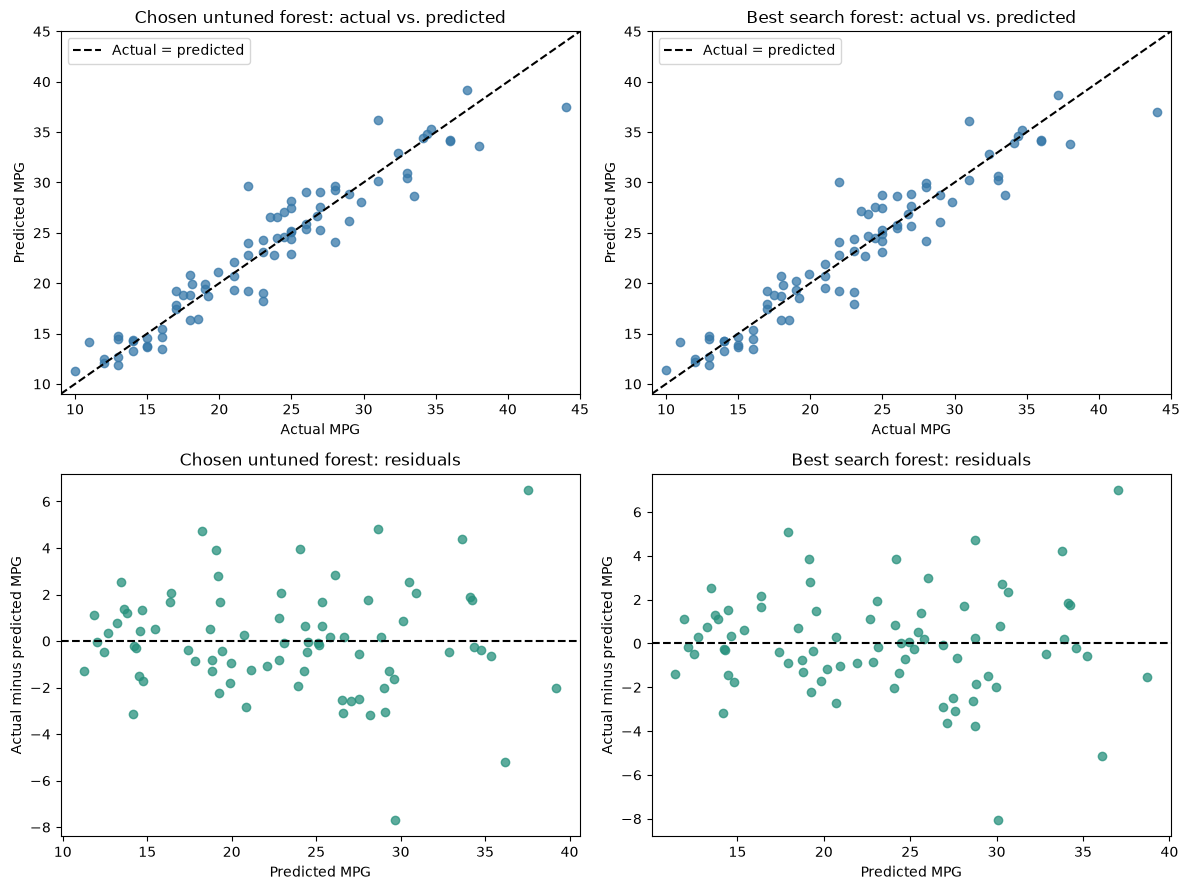

In [21]:
plot_models = ["Chosen untuned forest", "Best search forest"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
all_values = np.concatenate([y_test.to_numpy()] + [final_predictions[name] for name in plot_models])
lower, upper = all_values.min() - 1, all_values.max() + 1

for column, name in enumerate(plot_models):
    predictions = final_predictions[name]
    residuals = y_test.to_numpy() - predictions

    ax = axes[0, column]
    ax.scatter(y_test, predictions, alpha=0.75, color="#3778A8")
    ax.plot([lower, upper], [lower, upper], "--", color="black", label="Actual = predicted")
    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_title(name + ": actual vs. predicted")
    ax.set_xlabel("Actual MPG")
    ax.set_ylabel("Predicted MPG")
    ax.legend()

    ax = axes[1, column]
    ax.scatter(predictions, residuals, alpha=0.75, color="#27917D")
    ax.axhline(0, linestyle="--", color="black")
    ax.set_title(name + ": residuals")
    ax.set_xlabel("Predicted MPG")
    ax.set_ylabel("Actual minus predicted MPG")

fig.tight_layout()
plt.show()

### Descriptive checks on the frozen predictions

**AI feedback from visual inspection:** Most predictions are near the diagonal. Errors appear smaller at low MPG and more spread out at higher predicted MPG, without a clear, consistent direction of over- or underprediction. The band table below supports this impression, but the highest band contains few vehicles. These are descriptive observations, not a fitted error model or a formal bias test.

Some high-actual-MPG cases receive less extreme predictions. Averaging across tree leaves is a plausible contributor, rather than a demonstrated cause of any individual error or a universal property of every noisy predictor.

The final forests use all training vehicles, whereas each CV fit uses only four folds. More training data and variation in the 80-vehicle holdout are possible contributors to the CV/test difference; this comparison does not isolate their effects.

The percentile bootstrap below resamples the existing test absolute errors 20,000 times with seed 42. Its 95% interval describes test-sample uncertainty conditional on the fitted model, assuming these test vehicles represent independent draws. It does not include retraining, feature selection, or tuning uncertainty. All checks reuse stored predictions and do not change the model.

In [22]:
predicted_mpg_bins = [-np.inf, 16, 24, 32, np.inf]
predicted_mpg_labels = ["<16", "16–<24", "24–<32", "≥32"]
band_tables = {}
for name in plot_models:
    predictions = final_predictions[name]
    residuals = y_test.to_numpy() - predictions
    diagnostic_rows = pd.DataFrame({
        "Predicted MPG band": pd.cut(
            predictions, bins=predicted_mpg_bins, labels=predicted_mpg_labels, right=False,
        ),
        "residual": residuals,
        "absolute_error": np.abs(residuals),
    })
    band_tables[name] = diagnostic_rows.groupby("Predicted MPG band", observed=True).agg(
        Vehicles=("residual", "size"),
        MAE_MPG=("absolute_error", "mean"),
        Mean_residual_MPG=("residual", "mean"),
    )
residual_band_summary = pd.concat(band_tables, names=["Model"])
display(residual_band_summary.round(2))

cv_fit_sizes = [len(fit_indices) for fit_indices, _ in cv.split(X_train_selected)]
fixed_absolute_errors = np.abs(y_test.to_numpy() - final_predictions["Chosen untuned forest"])
bootstrap_rng = np.random.default_rng(42)
bootstrap_indices = bootstrap_rng.integers(
    0, len(fixed_absolute_errors), size=(20_000, len(fixed_absolute_errors)),
)
bootstrap_mae = fixed_absolute_errors[bootstrap_indices].mean(axis=1)
test_mae_interval = np.quantile(bootstrap_mae, [0.025, 0.975])
contains_cv = test_mae_interval[0] <= original_mae.mean() <= test_mae_interval[1]
display(Markdown(
    f"**Computed sample-size and uncertainty summary:** Final fit: "
    f"**{len(X_train_selected)} vehicles**; CV fits: "
    f"**{min(cv_fit_sizes)}–{max(cv_fit_sizes)} vehicles**; holdout: "
    f"**{len(y_test)} vehicles**. The chosen forest's percentile-bootstrap "
    f"95% MAE interval is approximately **{test_mae_interval[0]:.2f}–"
    f"{test_mae_interval[1]:.2f} MPG**. It "
    f"{'contains' if contains_cv else 'does not contain'} the primary CV mean MAE "
    f"of **{original_mae.mean():.2f} MPG**. This descriptive comparison is "
    f"not a test of development overfitting."
))

Vehicles  MAE_MPG  Mean_residual_MPG
Model                 Predicted MPG band                                      
Chosen untuned forest <16                       17     1.08               0.06
                      16–<24                    24     1.56               0.16
                      24–<32                    29     1.88              -0.34
                      ≥32                       10     2.35               0.55
Best search forest    <16                       17     1.09               0.04
                      16–<24                    23     1.54               0.29
                      24–<32                    30     1.98              -0.49
                      ≥32                       10     2.29               0.72

**Computed sample-size and uncertainty summary:** Final fit: **318 vehicles**; CV fits: **254–255 vehicles**; holdout: **80 vehicles**. The chosen forest's percentile-bootstrap 95% MAE interval is approximately **1.36–2.01 MPG**. It contains the primary CV mean MAE of **2.00 MPG**. This descriptive comparison is not a test of development overfitting.

### Ten largest absolute errors

The table includes the actual MPG, predicted MPG, signed residual, absolute error, and all six original input features. Its row index identifies a record in this dataset; it is not a vehicle name or an additional input feature.

We report the ten largest errors for the selected forest and for the assignment-required search model. Two previously selected records are discussed below. Separate **observation** (values and errors directly shown) from **hypothesis** (a possible explanation not demonstrated by this table).

In [23]:
test_error_tables = {}
for name in plot_models:
    errors = X_test_selected.copy()
    errors.insert(0, "actual_mpg", y_test)
    errors.insert(1, "predicted_mpg", final_predictions[name])
    errors.insert(2, "residual", errors["actual_mpg"] - errors["predicted_mpg"])
    errors.insert(3, "absolute_error", errors["residual"].abs())
    test_error_tables[name] = errors.sort_values("absolute_error", ascending=False)
    print(name + ": ten largest errors")
    display(test_error_tables[name].head(10).round(3))

print(f"Training MPG range: {y_train.min():.1f} to {y_train.max():.1f}")
print(f"Test MPG range: {y_test.min():.1f} to {y_test.max():.1f}")

# Preserve the prediction/error values for review without generating new predictions.
final_review_snapshot = {
    "metrics": final_test_metrics.to_dict(orient="index"),
    "cv_test_comparison": cv_test_comparison.to_dict(orient="index"),
    "largest_errors": {
        name: table.head(10).reset_index().to_dict(orient="records")
        for name, table in test_error_tables.items()
    },
}
print("Final predictions are fixed; no model changes follow from these diagnostics.")

# Reuse fixed predictions; recompute facts instead of hard-coding error order or values.
for case_index in [389, 394]:
    record = test_error_tables["Chosen untuned forest"].loc[case_index]
    direction = "underpredicted" if record["residual"] > 0 else "overpredicted"
    case_rank = test_error_tables["Chosen untuned forest"].index.get_loc(case_index) + 1
    display(Markdown(
        f"**Computed observation — row {case_index} ({direction}; error rank {case_rank}):** "
        f"Actual **{record['actual_mpg']:.1f} MPG**, predicted "
        f"**{record['predicted_mpg']:.2f} MPG**, residual "
        f"**{record['residual']:+.2f} MPG**. Inputs include "
        f"{record['cylinders']:.0f} cylinders, {record['horsepower']:.0f} horsepower, "
        f"weight {record['weight']:,.0f}, and model year {record['model-year']:.0f}."
    ))
    companion = test_error_tables["Best search forest"].loc[case_index]
    companion_rank = test_error_tables["Best search forest"].index.get_loc(case_index) + 1
    display(Markdown(
        f"For the assignment-required search model, this record has prediction "
        f"**{companion['predicted_mpg']:.2f} MPG**, residual "
        f"**{companion['residual']:+.2f} MPG**, and error rank **{companion_rank}**."
    ))

Chosen untuned forest: ten largest errors


,actual_mpg,predicted_mpg,residual,absolute_error,cylinders,displacement,horsepower,weight,acceleration,model-year
389,22.0,29.693,-7.693,7.693,6,232.0,112.0,2835,14.7,82
394,44.0,37.520,6.480,6.480,4,97.0,52.0,2130,24.6,82
377,31.0,36.187,-5.187,5.187,4,91.0,68.0,1970,17.6,82
238,33.5,28.674,4.826,4.826,4,98.0,83.0,2075,15.9,77
298,23.0,18.259,4.741,4.741,8,350.0,125.0,3900,17.4,79
383,38.0,33.628,4.372,4.372,4,91.0,67.0,1965,15.0,82
30,28.0,24.041,3.959,3.959,4,140.0,90.0,2264,15.5,71
101,23.0,19.070,3.930,3.930,6,198.0,95.0,2904,16.0,73
386,25.0,28.189,-3.189,3.189,6,181.0,110.0,2945,16.4,82
124,11.0,14.131,-3.131,3.131,8,350.0,180.0,3664,11.0,73


Best search forest: ten largest errors


,actual_mpg,predicted_mpg,residual,absolute_error,cylinders,displacement,horsepower,weight,acceleration,model-year
389,22.0,30.058,-8.058,8.058,6,232.0,112.0,2835,14.7,82
394,44.0,37.012,6.989,6.989,4,97.0,52.0,2130,24.6,82
377,31.0,36.127,-5.127,5.127,4,91.0,68.0,1970,17.6,82
298,23.0,17.912,5.088,5.088,8,350.0,125.0,3900,17.4,79
238,33.5,28.760,4.740,4.740,4,98.0,83.0,2075,15.9,77
383,38.0,33.790,4.210,4.210,4,91.0,67.0,1965,15.0,82
30,28.0,24.155,3.845,3.845,4,140.0,90.0,2264,15.5,71
101,23.0,19.166,3.834,3.834,6,198.0,95.0,2904,16.0,73
386,25.0,28.771,-3.771,3.771,6,181.0,110.0,2945,16.4,82
341,23.5,27.151,-3.651,3.651,6,173.0,110.0,2725,12.6,81


Training MPG range: 9.0 to 46.6
Test MPG range: 10.0 to 44.0
Final predictions are fixed; no model changes follow from these diagnostics.


**Computed observation — row 389 (overpredicted; error rank 1):** Actual **22.0 MPG**, predicted **29.69 MPG**, residual **-7.69 MPG**. Inputs include 6 cylinders, 112 horsepower, weight 2,835, and model year 82.

For the assignment-required search model, this record has prediction **30.06 MPG**, residual **-8.06 MPG**, and error rank **1**.

**Computed observation — row 394 (underpredicted; error rank 2):** Actual **44.0 MPG**, predicted **37.52 MPG**, residual **+6.48 MPG**. Inputs include 4 cylinders, 52 horsepower, weight 2,130, and model year 82.

For the assignment-required search model, this record has prediction **37.01 MPG**, residual **+6.99 MPG**, and error rank **2**.

### Final interpretation and error-case hypotheses

**Student interpretation:** The chosen forest performed strongly overall and substantially outperformed the mean baseline. Its test error was lower than its CV error, so the holdout does not show deterioration. A different mix of vehicles is one possible explanation for the difference. There are still substantial individual errors, and the overall score does not imply uniform accuracy.

**AI feedback:** Differences in training size and test-sample uncertainty are additional plausible contributors. Neither the CV/test gap nor the descriptive interval isolates a cause or proves an absence of selection overfitting. The model preference remains the choice made before testing.

**Student hypothesis — row 389:** The model may have relied heavily on the recent model year and relatively low weight for a six-cylinder vehicle, predicting better fuel economy than observed. Missing information such as gearing, transmission, engine design, or condition could contribute to the error.

**Student hypothesis — row 394:** The model may have averaged this unusually efficient, light, low-power vehicle toward less extreme MPG values. Unmeasured fuel type, transmission, aerodynamics, or gearing could help explain its higher observed MPG.

**AI feedback:** These explanations are speculative. The dataset does not establish those missing attributes for either record, and no feature has been shown to cause either error. The generated observations above report the actual values, signed residuals, and error ranks for this execution.

## 14. Conclusion and AI reflection

*AI-assisted draft answers based on the recorded discussion and results. The first-person reflections are for student review.*

### AI reflection

I asked AI to break the assignment into steps and help me understand the purpose of the experiments, rather than only generate code. It helped suggest four interpretable ratios, explain the two importance methods, organize feature-subset comparisons, and construct a manageable randomized search. I accepted testing all four ratios because each had a reasonable meaning, but I did not assume they would improve prediction. We compared the original and engineered representations with the same untuned forest settings, training-data CV folds, and MAE metric, with median imputation fitted within each fold. The combined feature experiment showed essentially unchanged error. I then proposed removing power-to-weight from the full set and adding it alone to the original six, followed by repeated CV to examine sensitivity to the partitions. The differences were small, so I chose the original six for simplicity. The planned hyperparameter search also did not show a practically meaningful improvement, and I selected the untuned forest before looking at test results.

One AI suggestion I did not retain in the final model was power-to-weight as an additional predictor. I accepted testing the idea, but the controlled comparisons did not show enough incremental benefit to justify keeping it. I also modified the AI-assisted explanation that its weak importance reflected redundancy. The training correlations supported overlap for some displacement-based ratios, but did not establish that explanation for power-to-weight. I changed the conclusion to say that the tested ratio added little predictive benefit under these settings, without claiming that we had proved why. This project showed me that AI suggestions need evidence: meaningful formulas, low importance, and more tuning do not automatically produce a better model.

### Final workflow reflection

I began by inspecting the data and creating the fixed train/test split. The mean predictor established what could be achieved without vehicle features, while the untuned Random Forest provided a fair model baseline. I then engineered interpretable ratios and compared the expanded representation against the original inputs under the same training-data CV procedure. Engineering before selection preserved the opportunity to construct features from raw ingredients. For example, discarding cylinders entirely would prevent constructing displacement per cylinder; this illustrates the logic, rather than showing that cylinders actually had low importance in our results.

Next, I used built-in and validation permutation importance to suggest feature-selection experiments, not to automatically delete low-ranked columns. I compared candidate subsets and paired fold differences, considered the small gains alongside complexity, and froze the original six features before tuning. Randomized search then tested a bounded set of hyperparameter combinations. I compared its winner with the untuned baseline and kept the untuned forest as my preferred model. Only after those decisions were fixed did I evaluate the test set, reporting both fixed forests and the mean baseline and reusing their predictions for the plots and error analysis.

The order matters because it makes the comparisons easier to interpret and keeps the final test results from steering model development. The assignment-required initial inspection, descriptive statistics, and MPG histogram used all 398 rows before splitting. No modeling decision used the test rows. After the split, feature engineering decisions, importance analysis, feature selection, the student-designed experiment, and tuning all used training data. The repeated-CV follow-up hypothesis was informed by the initial comparison, and its folds are dependent, so I treat it as a sensitivity check. Repeated development comparisons can still make CV results optimistic. The later test diagnostics describe the fixed predictions and do not justify changing the model. My main lesson is that additional complexity is worthwhile only when the evidence supports a useful improvement; a well-controlled experiment that finds little benefit is still a valuable result.

### Hyperparameter explanations

*AI-assisted draft explanations for review; the student's earlier `min_samples_leaf` explanation remains in Section 11.*

- **`n_estimators`:** This controls how many trees the forest averages. More trees can make predictions more stable, but take longer to train and predict and do not necessarily improve accuracy.
- **`max_depth`:** This limits how many levels each tree can grow. Greater depth allows more detailed rules that can fit noise; a small limit can miss real patterns. `None` removes the depth cap, while other stopping rules still apply.
- **`max_features`:** This sets how many candidate inputs are considered at each split. Considering fewer can make trees less similar, but may weaken individual splits; using all inputs gives each split more choices.
- **`min_samples_split`:** This is the minimum number of training observations a node needs before a split can be considered. Raising it restricts tree growth and can reduce overfitting, but too large a value can underfit. It does not guarantee a split or set the minimum size of both resulting leaves.

Definitions checked against the [official RandomForestRegressor documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).